# Task 3 — Synthetic demonstration
David Yakubov · Research Methods

**All records are invented Task 2 fixtures. No real experiment or hypothesis test is reported.** We retain learning gain, task time and critical thinking from Task 2. This notebook uses deterministic calculations; no random seed is needed.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if not (ROOT / "src/benchmark.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "src/benchmark.py").exists(), "Open from project root or notebooks folder"
sys.path.insert(0, str(ROOT / "src"))
from process_data import run
from visualize import create_figures
print("Python:", sys.version.split()[0])
print("Deterministic fixture; no random sampling or bootstrap.")

Python: 3.12.14
Deterministic fixture; no random sampling or bootstrap.


## 1. Ingestion and warm-up assessment
Load JSONL and inspect the synthetic provenance and phases. Educational measurements have no hardware cold-start phase. No rows will be discarded as warm-up; non-evaluation records are rejected. The original Task 2 validator checks the numeric ranges and duplicate/missing values.

In [2]:
raw = pd.read_json(ROOT / "data/raw/test_run.jsonl", lines=True)
display(raw)
print("Phase counts:", raw["phase"].value_counts().to_dict())
rows, aggregates, summary = run()
print("Raw:", len(raw), "Retained:", len(rows), "Excluded:", summary["task3"]["excluded_records"])
print(summary["task3"]["warmup"])

,participant_id,group,pretest_score,posttest_score,task_minutes,critical_thinking_score,data_kind,phase
0,S001,traditional,50,62,32,12,synthetic_smoke_test,evaluation
1,S002,traditional,60,68,35,13,synthetic_smoke_test,evaluation
2,S003,traditional,55,65,30,11,synthetic_smoke_test,evaluation
3,S004,traditional,70,78,34,14,synthetic_smoke_test,evaluation
4,S005,traditional,45,58,37,10,synthetic_smoke_test,evaluation
5,S006,genai,50,68,27,13,synthetic_smoke_test,evaluation
6,S007,genai,60,75,28,14,synthetic_smoke_test,evaluation
7,S008,genai,55,72,26,12,synthetic_smoke_test,evaluation
8,S009,genai,70,83,29,15,synthetic_smoke_test,evaluation
9,S010,genai,45,62,31,11,synthetic_smoke_test,evaluation


Phase counts: {'evaluation': 10}
Raw: 10 Retained: 10 Excluded: 0
Not applicable: educational measurements, not inference latency.


## 2. Descriptive aggregation
Gain = post-test − pre-test. Sample SD uses n−1 and measures spread, not confidence. We report means, medians, SD and ranges; no significance tests or bootstrap intervals are used.

In [3]:
metrics = pd.DataFrame(aggregates)
display(metrics.round(3))
differences = pd.Series(summary["treatment_minus_control"], name="GenAI minus traditional")
display(differences.to_frame().round(3))

,group,metric,n,mean,median,sd,minimum,maximum
0,traditional,pretest_score,5,56.0,55.0,9.618,45.0,70.0
1,traditional,posttest_score,5,66.2,65.0,7.563,58.0,78.0
2,traditional,task_minutes,5,33.6,34.0,2.702,30.0,37.0
3,traditional,critical_thinking_score,5,12.0,12.0,1.581,10.0,14.0
4,traditional,learning_gain_percentage_points,5,10.2,10.0,2.280,8.0,13.0
5,genai,pretest_score,5,56.0,55.0,9.618,45.0,70.0
6,genai,posttest_score,5,72.0,72.0,7.842,62.0,83.0
7,genai,task_minutes,5,28.2,28.0,1.924,26.0,31.0
8,genai,critical_thinking_score,5,13.0,13.0,1.581,11.0,15.0
9,genai,learning_gain_percentage_points,5,16.0,17.0,2.000,13.0,18.0


,GenAI minus traditional
pretest_score,0.0
posttest_score,5.8
task_minutes,-5.4
critical_thinking_score,1.0
learning_gain_percentage_points,5.8


## 3. Guardrails
The −1 point critical-thinking margin is unchanged. A descriptive pass does not demonstrate non-inferiority. Assessment adherence cannot be checked from this fixture.

In [4]:
print(json.dumps(summary["guardrails"], indent=2))
print("Time-capped rows:", {g: x["time_capped_count"] for g, x in summary["groups"].items()})
print("Input SHA256:", summary["task3"]["raw_sha256"])

{
  "input_validation_passed": true,
  "critical_thinking_descriptive_check": true,
  "critical_thinking_margin_points": 1,
  "assessment_no_ai_adherence": "not assessed by this script",
  "note": "A descriptive mean check does not establish statistical non-inferiority."
}
Time-capped rows: {'traditional': 0, 'genai': 0}
Input SHA256: 581199cdee63761eba26eed23b03c9f71e64f6ac11e54d0f9e69708517a748bd


## 4. Figures and export
Two plots show individual records and mean ±1 sample SD, with units and distinct marker shapes. Each is saved as 300-DPI PNG and vector PDF. They depict fixture variation, not uncertainty about a real population.

reports\figures\fig1_learning_gain.png


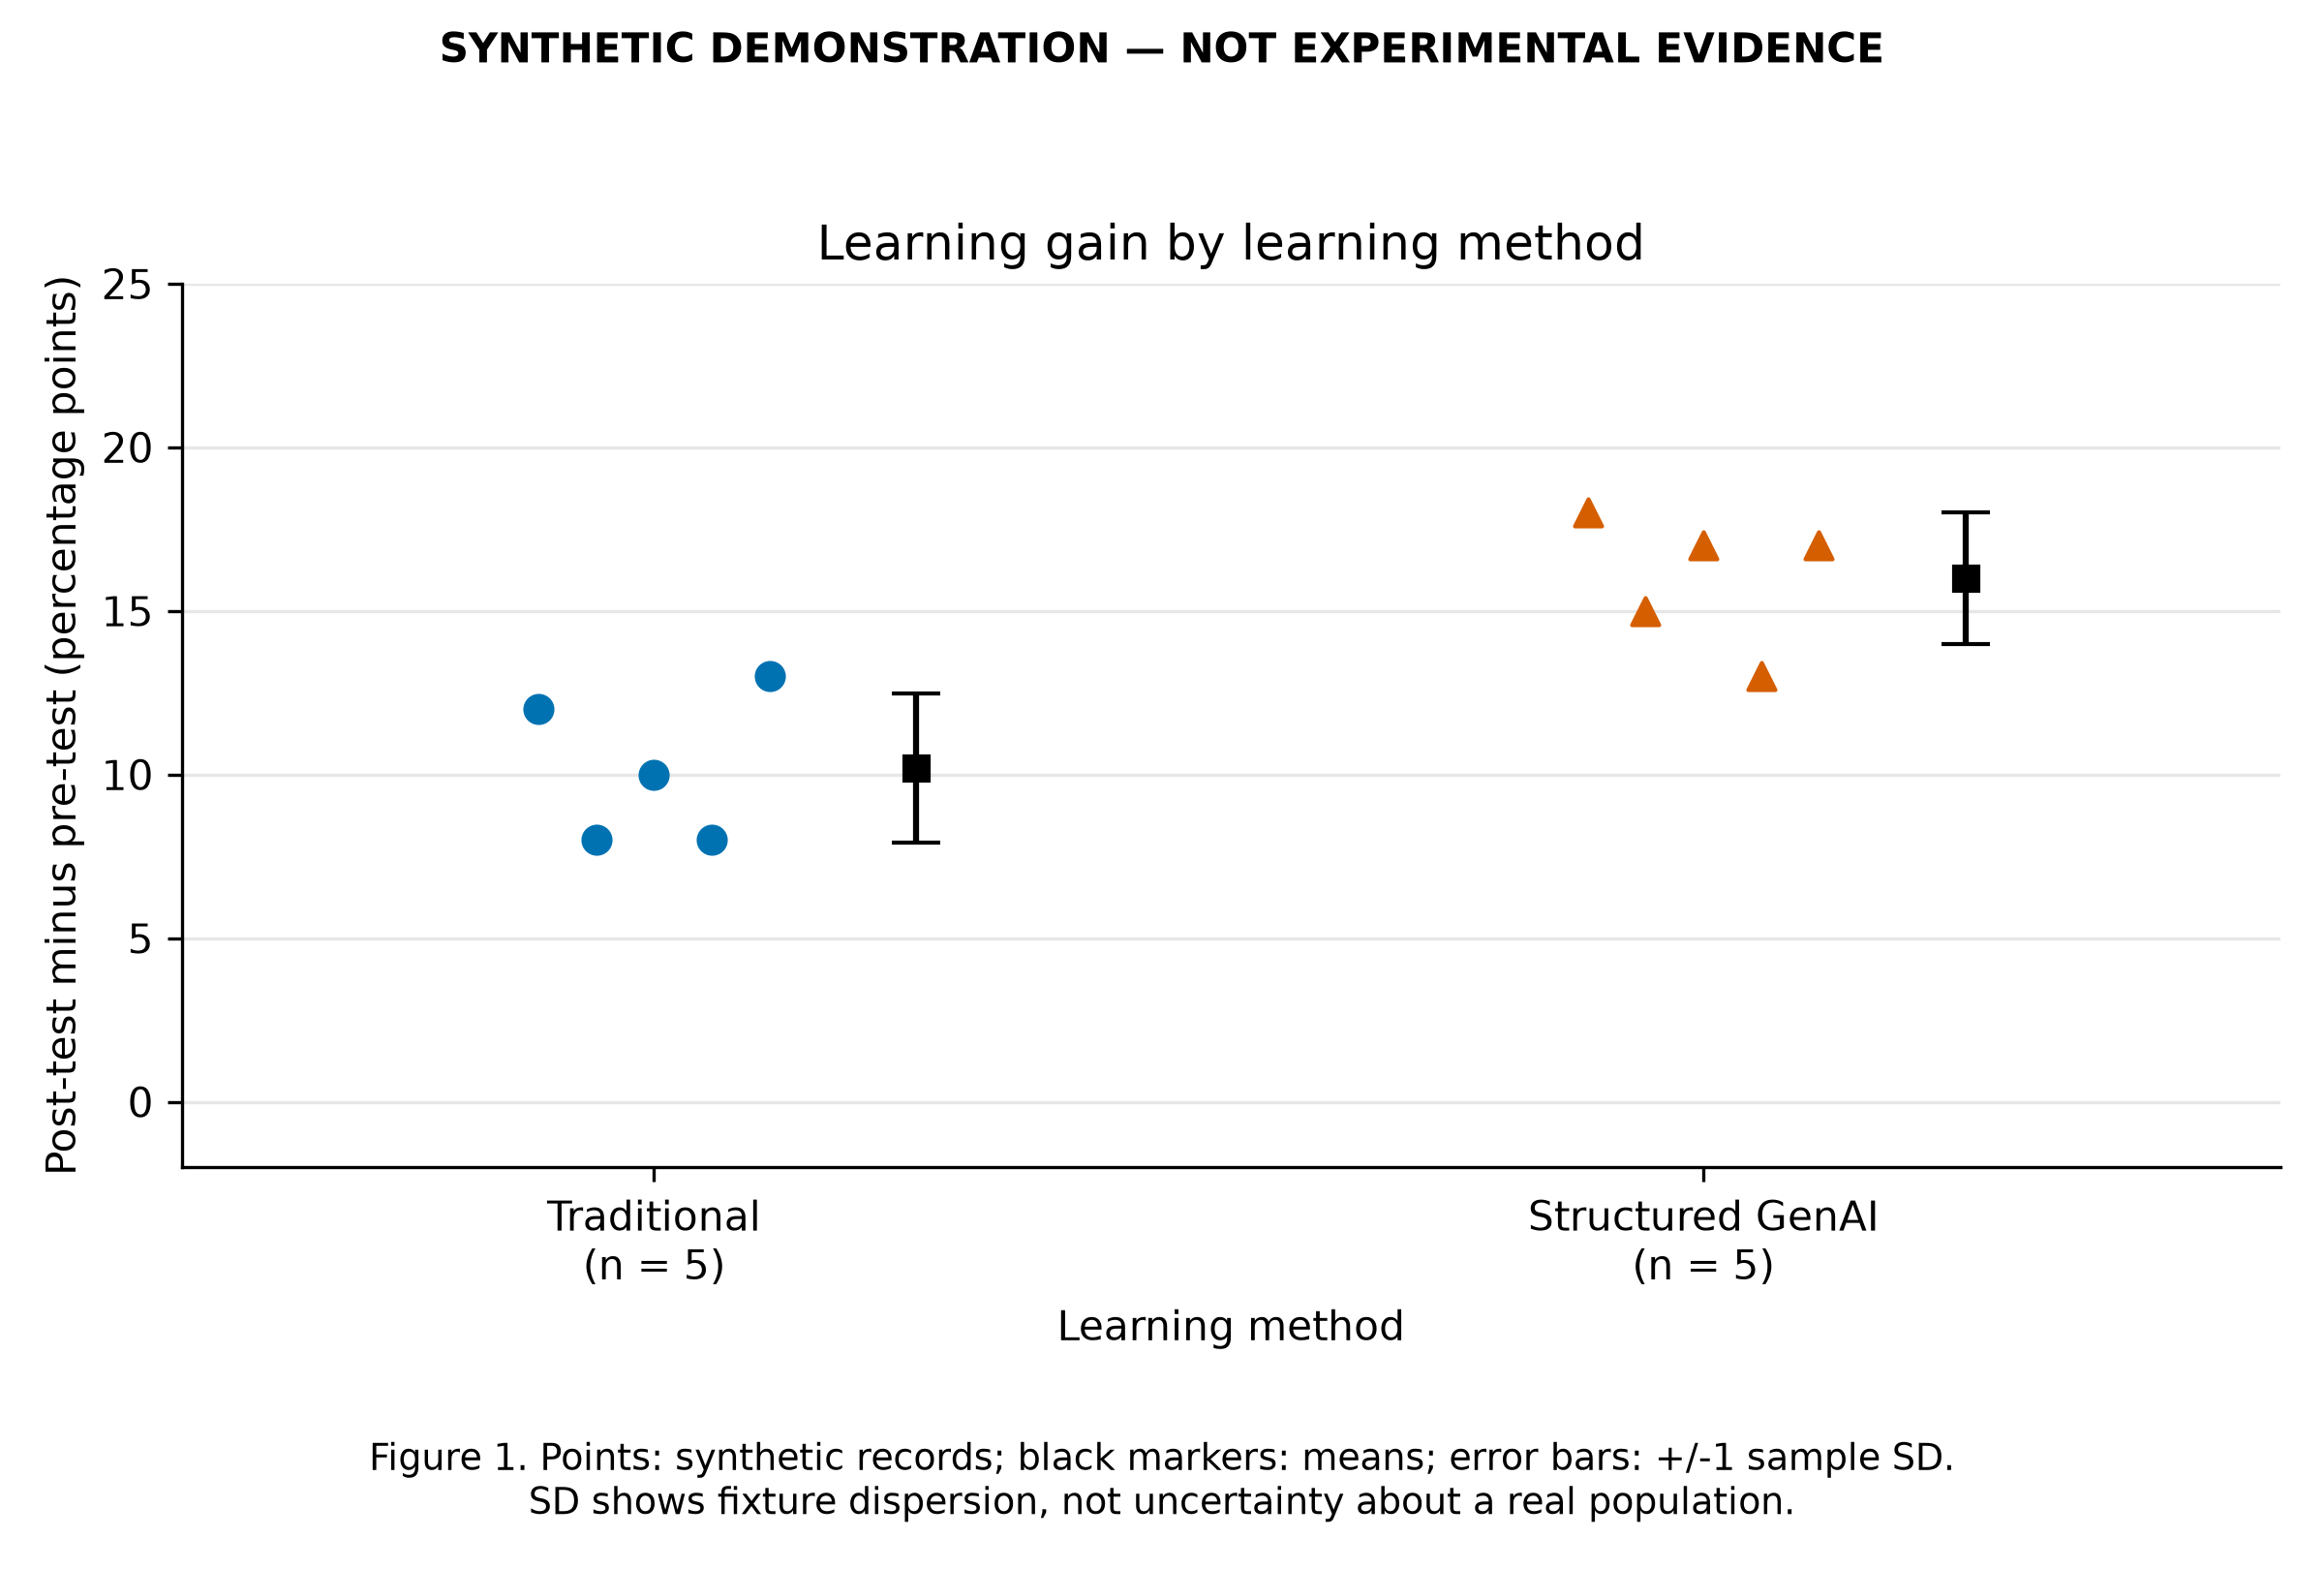

reports\figures\fig1_learning_gain.pdf
reports\figures\fig2_task_time.png


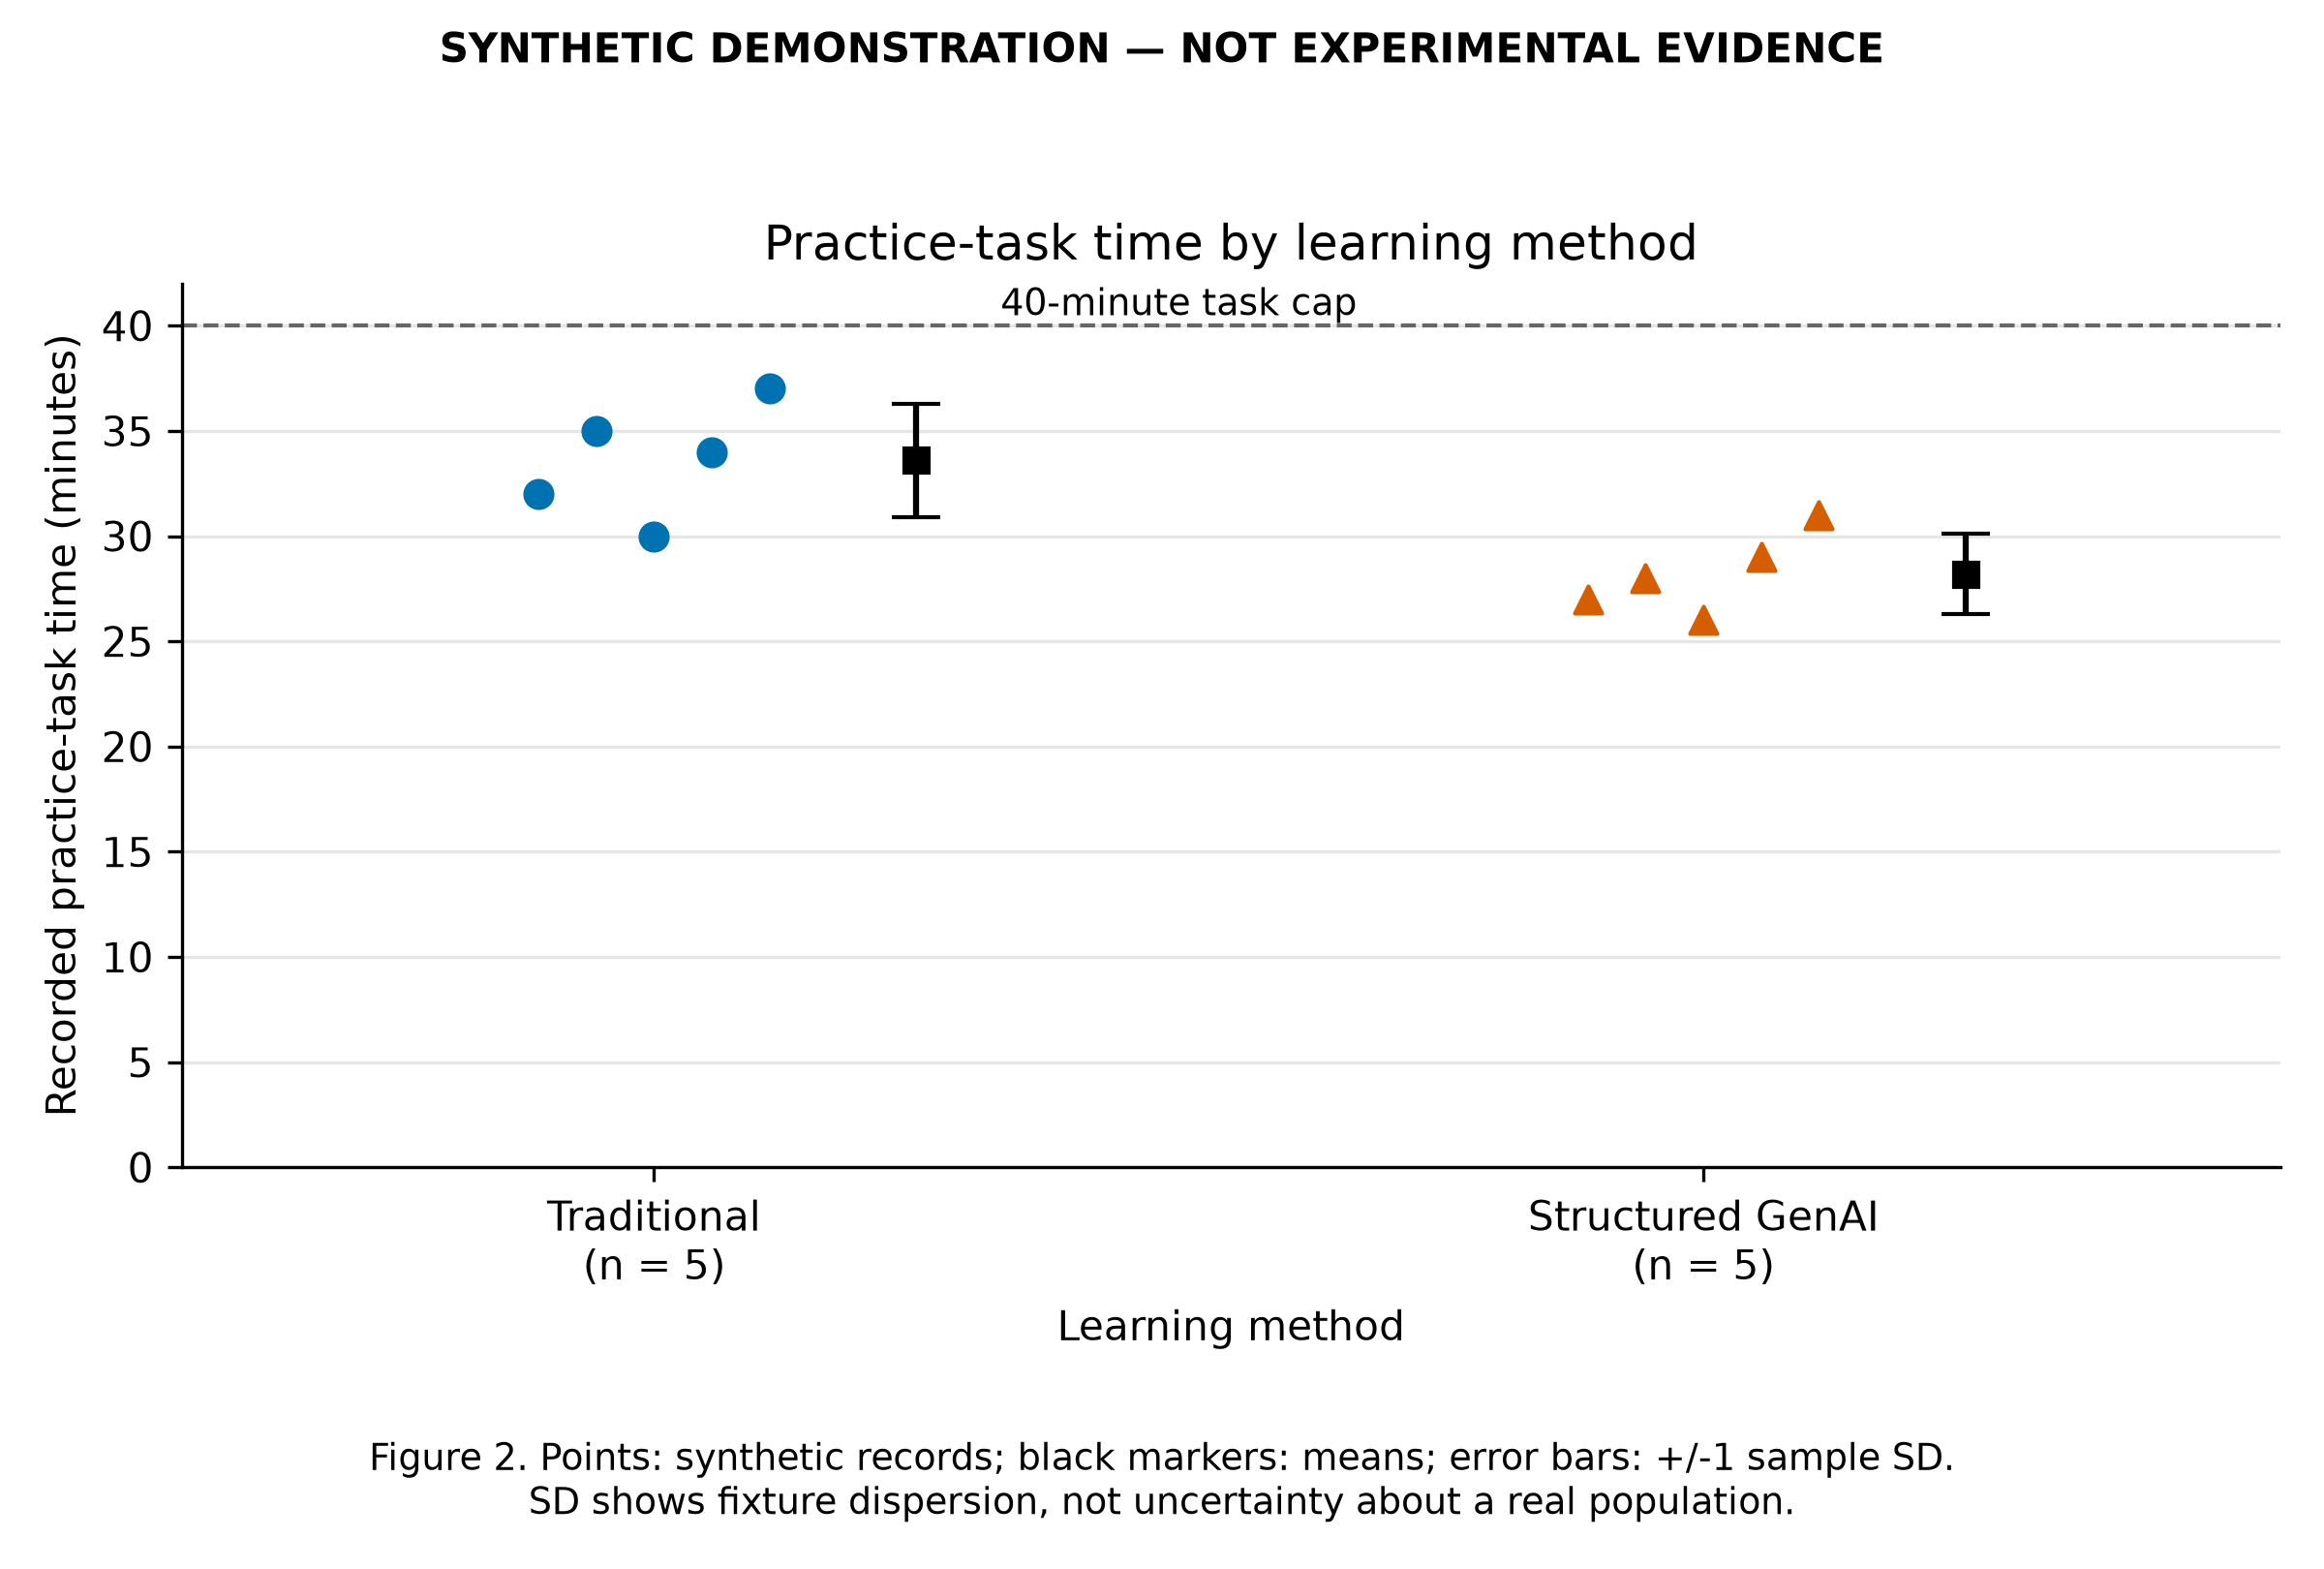

reports\figures\fig2_task_time.pdf


In [5]:
paths = create_figures(rows, aggregates)
for path in paths:
    print(path.relative_to(ROOT))
    if path.suffix == ".png":
        display(Image(filename=str(path), width=800))

## 5. Interpretation and formal model
The fixture gives a gain difference of +5.8 percentage points, time difference of −5.4 minutes and critical-thinking difference of +1.0 point. These values were encoded in invented data; **no hypothesis is confirmed**. The intended real pilot remains 40 students, not these 10 rows.

The [formal model](../docs/domain_model.md) uses group means to minimize squared error in gain. No LLM training occurs. Future real-data analysis still needs protocol completion, participant recruitment and the inferential procedures described in Task 2. This demonstration intentionally omits those expanded analyses.